# Synthetic Benchmark Networks for District Heating Systems
### Working notebook — Methodology II (algorithmic generation of TG/CS benchmark archetypes)


This notebook consolidates the generation pipeline described in **Section 5 (Methodology for
network archetypes generation)**:

1. **District Synthesis** — procedural urban district with centreline street grid and
   consumer substations allocated proportionally to block frontage (`DistrictGenerator`).
2. **Support Street Graph** — `networkx` graph of the street centreline network, with
   `shapely` edge geometries enabling downstream point projection (`StreetGraphBuilder`).
3. **Thermal Network Construction** — orthogonal projection of substations
   and heat source(s) onto the street graph (edge splitting), followed by an approximate
   Steiner Minimal Tree (SMT) spanning all terminals (`ThermalNetworkBuilder`).

Loop augmentation (ring/meshed topologies, Methodology I Rule 3 / Methodology II Step 3
second half) is **not yet implemented** in this notebook — it is the next development
step, to be added as a `MeshAugmenter` class operating on the radial base produced here.

> **Status**: Step 1 (street graph) and Step 2+3 radial (projection + SMT) are implemented
> and tested on medium-scale (100 substations) and large-scale (500 substations) districts.

## 0. Environment setup

In [90]:
import math
import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from shapely.geometry import Point, LineString
from networkx.algorithms.approximation import steiner_tree as nx_steiner_tree

## 1. District Synthesis — `DistrictGenerator`

In [91]:
# =====================================================================
# 1. DISTRICT GENERATOR
# =====================================================================
class DistrictGenerator:
    """
    Generates a synthetic urban district grid where roads are modelled as
    single-line centrelines to avoid double-pipe routing artefacts.

    Parameters
    ----------
    width, height    : footprint dimensions [m]
    rows, cols       : number of block rows/columns
    street_width     : uniform street width [m]
    n_substations    : total number of consumer substations
    block_variation  : relative variation of block dimensions (±fraction)
    perturbation     : max jitter on building position along frontage [m]
    seed             : random seed for full reproducibility
    """

    def __init__(self, width=1200, height=800, rows=5, cols=7,
                 street_width=15, n_substations=100,
                 block_variation=0.12, perturbation=5, seed=42):
        self.width           = width
        self.height          = height
        self.rows            = rows
        self.cols            = cols
        self.street_width    = street_width
        self.n_substations   = n_substations
        self.block_variation = block_variation
        self.perturbation    = perturbation
        self.seed            = seed

        random.seed(seed)
        self.blocks       = []
        self.buildings    = []
        self.street_nodes = {}
        self.street_edges = []
        self.street_graph = nx.Graph()

    # ------------------------------------------------------------------
    def random_partition(self, total, n):
        mean   = total / n
        values = [mean * (1 + random.uniform(-self.block_variation,
                                              self.block_variation))
                  for _ in range(n)]
        scale  = total / sum(values)
        values = [v * scale for v in values]
        values[-1] = total - sum(values[:-1])
        return values

    # ------------------------------------------------------------------
    def build_street_grid(self):
        usable_w = self.width  - (self.cols + 1) * self.street_width
        usable_h = self.height - (self.rows  + 1) * self.street_width

        self.block_widths  = self.random_partition(usable_w, self.cols)
        self.block_heights = self.random_partition(usable_h, self.rows)

        # Block boundary coordinates
        self.x = [0]
        for bw in self.block_widths:
            self.x.append(self.x[-1] + self.street_width)
            self.x.append(self.x[-1] + bw)

        self.y = [0]
        for bh in self.block_heights:
            self.y.append(self.y[-1] + self.street_width)
            self.y.append(self.y[-1] + bh)

        # Street centreline coordinates
        cx = [(self.x[i] + self.x[i+1]) / 2 if i+1 < len(self.x)
              else self.x[i] for i in range(0, len(self.x), 2)]
        cy = [(self.y[j] + self.y[j+1]) / 2 if j+1 < len(self.y)
              else self.y[j] for j in range(0, len(self.y), 2)]

        for i, x in enumerate(cx):
            for j, y in enumerate(cy):
                self.street_nodes[(i, j)] = (x, y)

        for i in range(len(cx) - 1):
            for j in range(len(cy)):
                self.street_edges.append(((i, j), (i+1, j)))
        for i in range(len(cx)):
            for j in range(len(cy) - 1):
                self.street_edges.append(((i, j), (i, j+1)))

        for node, pos in self.street_nodes.items():
            self.street_graph.add_node(node, pos=pos)
        for n1, n2 in self.street_edges:
            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]
            self.street_graph.add_edge(n1, n2,
                                       length=abs(x2-x1)+abs(y2-y1))

    # ------------------------------------------------------------------
    def build_blocks(self):
        block_id = 0
        for c in range(self.cols):
            for r in range(self.rows):
                x0 = self.x[2*c + 1]
                y0 = self.y[2*r + 1]
                self.blocks.append({
                    "id": block_id, "x": x0, "y": y0,
                    "col": c, "row": r,
                    "width":  self.block_widths[c],
                    "height": self.block_heights[r],
                    "area":   self.block_widths[c] * self.block_heights[r],
                })
                block_id += 1

    # ------------------------------------------------------------------
    def build_buildings(self):
        building_id = 0
        block_index = 0
        MARGIN  = self.street_width * 0.5
        MIN_GAP = 15.0

        for c in range(self.cols):
            for r in range(self.rows):
                block = self.blocks[block_index]
                x0, y0 = block["x"], block["y"]
                bw, bh  = block["width"], block["height"]

                available = []
                if r < self.rows - 1: available.append("N")
                if r > 0:             available.append("S")
                if c < self.cols - 1: available.append("E")
                if c > 0:             available.append("W")

                if not available:
                    block_index += 1
                    continue

                n = self._allocation[block_index]
                front_lens   = {"N": bw, "S": bw, "E": bh, "W": bh}
                avail_lens   = {s: front_lens[s] for s in available}
                total_len    = sum(avail_lens.values())
                sides_sorted = sorted(avail_lens, key=avail_lens.get,
                                      reverse=True)
                front_counts = {}
                assigned     = 0
                for i, side in enumerate(sides_sorted):
                    if i == len(sides_sorted) - 1:
                        front_counts[side] = n - assigned
                    else:
                        cnt = max(0, round(n * avail_lens[side] / total_len))
                        front_counts[side] = cnt
                        assigned += cnt

                for side, cnt in front_counts.items():
                    if cnt <= 0:
                        continue
                    if side in ("N", "S"):
                        axis_len, axis_start = bw, x0
                        fixed = y0 + bh - MARGIN if side == "N" \
                                else y0 + MARGIN
                    else:
                        axis_len, axis_start = bh, y0
                        fixed = x0 + bw - MARGIN if side == "E" \
                                else x0 + MARGIN

                    spacing = max(axis_len / (cnt + 1), MIN_GAP)
                    for k in range(cnt):
                        pos = axis_start + spacing * (k + 1)
                        pos += random.uniform(-self.perturbation,
                                              self.perturbation)
                        pos = max(axis_start + MIN_GAP,
                                  min(axis_start + axis_len - MIN_GAP, pos))
                        bx, by = (pos, fixed) if side in ("N", "S") \
                                  else (fixed, pos)
                        self.buildings.append({
                            "id": building_id,
                            "x": bx, "y": by,
                            "block": block["id"],
                        })
                        building_id += 1
                block_index += 1

    # ------------------------------------------------------------------
    def generate(self):
        self.build_street_grid()
        self.build_blocks()

        n_blocks    = len(self.blocks)
        avail_cnts  = []
        for idx in range(n_blocks):
            c, r = idx // self.rows, idx % self.rows
            cnt  = sum([r < self.rows-1, r > 0,
                        c < self.cols-1, c > 0])
            avail_cnts.append(max(cnt, 1))

        total_avail = sum(avail_cnts)
        raw         = [self.n_substations * a / total_avail
                       for a in avail_cnts]
        allocation  = [max(1, round(v)) for v in raw]
        diff        = self.n_substations - sum(allocation)
        for i in range(abs(diff)):
            allocation[i % n_blocks] += 1 if diff > 0 else -1
            allocation[i % n_blocks]  = max(0, allocation[i % n_blocks])

        self._allocation = allocation
        self.build_buildings()
        return self

    # ------------------------------------------------------------------
    def plot_district(self, ax=None, show=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))
        ax.set_facecolor('#AAAAAA')
        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, b in enumerate(self.blocks):
            ax.add_patch(patches.Rectangle(
                (b["x"], b["y"]), b["width"], b["height"],
                facecolor=colors[idx % len(colors)],
                edgecolor='none', zorder=1))
        xs = [b["x"] for b in self.buildings]
        ys = [b["y"] for b in self.buildings]
        ax.scatter(xs, ys, color='#CC2200', s=50, marker='s',
                   edgecolors='white', linewidths=0.4, zorder=5,
                   label='Substations')
        ax.set_xlim(-20, self.width+20)
        ax.set_ylim(-20, self.height+20)
        ax.set_title("Synthetic Urban District", fontweight="bold", fontsize=12)
        ax.set_aspect('equal'); ax.axis('off')
        if show:
            plt.tight_layout(); plt.show()

district = DistrictGenerator(
    width=1200, height=800,
    rows=5, cols=7,
    street_width=15,
    n_substations=100,
    block_variation=0.25,
    perturbation=7,
    seed=42,
)
district.generate()
district.plot_district()
### 1.1 Demo — medium-scale district (100 substations)


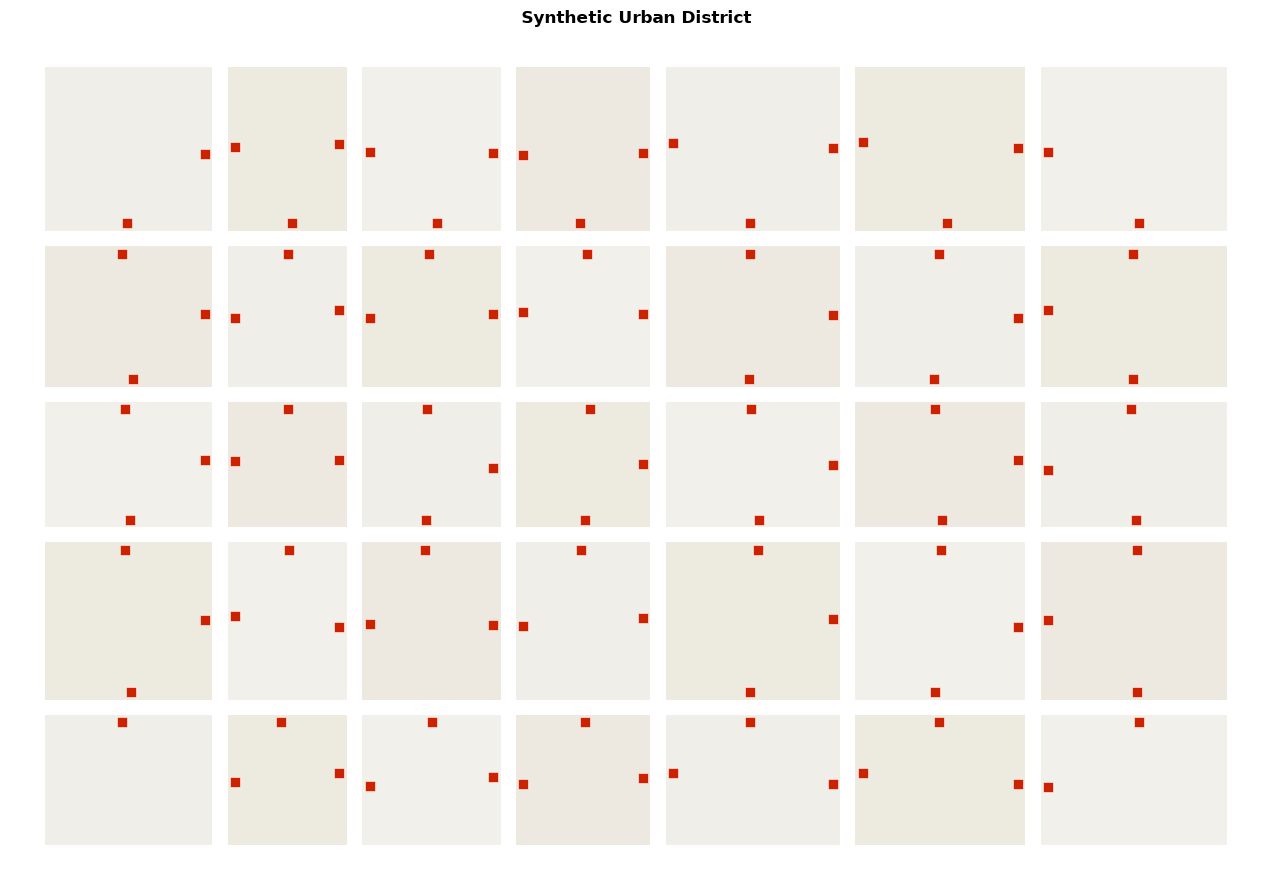

In [92]:
district = DistrictGenerator(
    width=1200, height=800,
    rows=5, cols=7,
    street_width=15,
    n_substations=100,
    block_variation=0.25,
    perturbation=7,
    seed=42,
)
district.generate()
district.plot_district()


## 2. Support Street Graph — `StreetGraphBuilder`

Builds the `networkx.Graph` support structure over the street centreline network:
- **nodes** = street intersections
- **edges** = individual street segments (one per street, no duplicates), each carrying
  `length` and a `shapely.LineString` `geometry` used for orthogonal point projection
  in Step 2/3.

The graph is validated for connectivity, a necessary condition for the Steiner Minimal
Tree computation.

In [93]:
# =====================================================================
# 2. STREET GRAPH BUILDER
# =====================================================================
class StreetGraphBuilder:
    """
    Builds and validates the support street graph starting from an already
    generated DistrictGenerator (after calling .generate()).
    """

    def __init__(self, district: DistrictGenerator):
        if not district.street_nodes:
            raise ValueError(
                "The district has not been generated: call "
                "district.generate() before building the support "
                "street graph."
            )
        self.district = district
        self.graph = nx.Graph()

    # ------------------------------------------------------------------
    def build(self) -> nx.Graph:
        d = self.district

        # --- nodes: street intersections ---
        for node_id, (x, y) in d.street_nodes.items():
            self.graph.add_node(node_id, pos=(x, y), kind="intersection")

        # --- edges: street segments (one per street, no duplicates) ---
        for n1, n2 in d.street_edges:
            x1, y1 = d.street_nodes[n1]
            x2, y2 = d.street_nodes[n2]
            length = math.hypot(x2 - x1, y2 - y1)
            geometry = LineString([(x1, y1), (x2, y2)])
            self.graph.add_edge(n1, n2, length=length, geometry=geometry,
                                 kind="street")

        self._validate()
        return self.graph

    # ------------------------------------------------------------------
    def _validate(self):
        if self.graph.number_of_nodes() == 0:
            raise ValueError("The support street graph is empty.")

        if not nx.is_connected(self.graph):
            n_comp = nx.number_connected_components(self.graph)
            raise ValueError(
                f"The support street graph is not connected "
                f"({n_comp} separate components): the Steiner Minimal Tree "
                f"(Step 3) requires a connected graph. Check the "
                f"grid generation parameters in "
                f"DistrictGenerator (rows, cols, street_width)."
            )

        # degenerate edges (near-zero length) are flagged but not blocking
        zero_len = [
            (u, v) for u, v, l in self.graph.edges(data="length")
            if l is not None and l < 1e-6
        ]
        if zero_len:
            print(f"[WARN] {len(zero_len)} near-zero-length edges detected "
                  f"in the street graph (possible geometric artefact).")

    # ------------------------------------------------------------------
    def stats(self) -> dict:
        lengths = list(nx.get_edge_attributes(self.graph, "length").values())
        return {
            "n_nodes": self.graph.number_of_nodes(),
            "n_edges": self.graph.number_of_edges(),
            "total_length_m": sum(lengths),
            "mean_edge_length_m": sum(lengths) / len(lengths) if lengths else 0.0,
            "is_connected": nx.is_connected(self.graph),
            "n_components": nx.number_connected_components(self.graph),
        }

    # ------------------------------------------------------------------
    def plot(self, ax=None, show=True, with_district=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))

        if with_district:
            self.district.plot_district(ax=ax, show=False)

        pos = nx.get_node_attributes(self.graph, "pos")
        nx.draw_networkx_edges(self.graph, pos, ax=ax, edge_color="#2266AA",
                                width=1.4, alpha=0.85)
        nx.draw_networkx_nodes(self.graph, pos, ax=ax, node_color="#2266AA",
                                node_size=18, linewidths=0)

        ax.set_title("Support street graph (Step 1)",
                      fontweight="bold", fontsize=12)
        if show:
            plt.tight_layout()
            plt.show()
        return ax

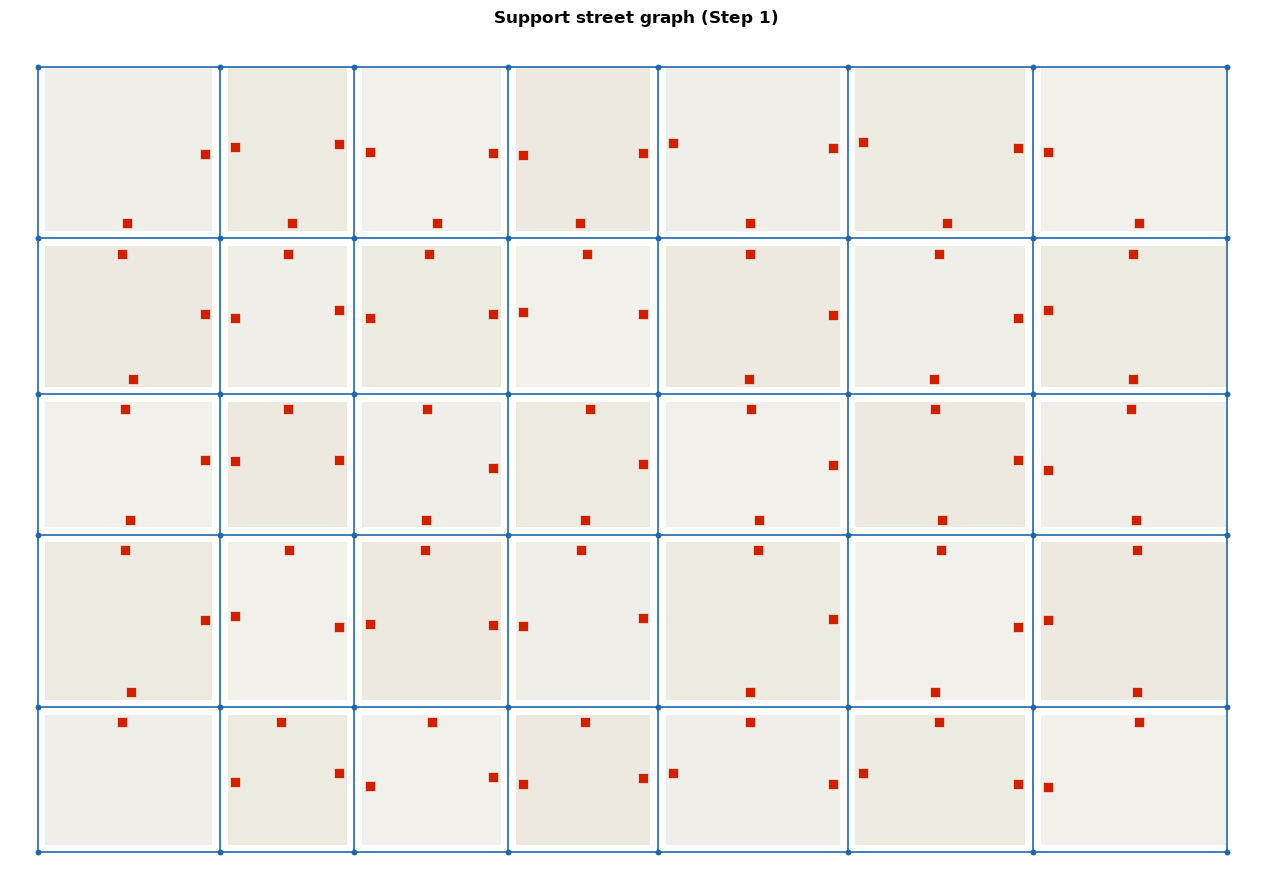

<Axes: title={'center': 'Support street graph (Step 1)'}>

In [94]:
builder_sg = StreetGraphBuilder(district)
street_graph = builder_sg.build()
builder_sg.stats()
builder_sg.plot()

## 3. Thermal Network Construction — `ThermalNetworkBuilder` (radial base)

Implements:

- ** Step
2 — Building
allocation **: substations and heat
source(s)
are
orthogonally
projected
onto
the
nearest
street
edge;
the
projection
splits
the
edge
at
the
projection
point, creating
a
new
graph
node(`kind = 'substation'
` or `kind = 'source'
`).
- ** Step
3 — Network
topology
optimisation(radial
base) **: the
primary
distribution
network is computed as an
approximate
Steiner
Minimal
Tree(Mehlhorn
's algorithm) on
the
projected
graph,
with terminals = source node(s) + all substation nodes.This is
the `L = 0` independent-loop radial base topology; ring / meshed augmentation is a
separate, not -yet-implemented step.

The number and position of heat sources are free parameters passed by the caller, so
the same class serves every generation archetype of the benchmark family (e.g.one
centralised source for 3GDH, two spatially distributed sources for 4GDH, etc.)



In [95]:
# =====================================================================
# 3. THERMAL NETWORK BUILDER
# =====================================================================
class ThermalNetworkBuilder:
    """
    Builds the primary distribution network topology of a district heating
    network (DHN), starting from the support street graph (Step 1) and the
    substation set of a generated synthetic district.

    Parameters
    ----------
    district : DistrictGenerator
        Already generated synthetic district (buildings + street blocks).
    street_graph : networkx.Graph
        Support street graph produced by StreetGraphBuilder.build() (Step
        1). Edges must carry 'geometry' (shapely LineString) and 'length'.
    source_positions : list[tuple[float, float]]
        (x, y) coordinates of the heat source(s), chosen by the caller.
        The number of heat sources equals len(source_positions).
    """

    def __init__(self, district: DistrictGenerator, street_graph: nx.Graph,
                 source_positions):
        if street_graph.number_of_nodes() == 0:
            raise ValueError(
                "Empty street graph: build it with StreetGraphBuilder "
                "before instantiating ThermalNetworkBuilder."
            )
        if not source_positions:
            raise ValueError(
                "At least one source position must be provided "
                "(list of (x, y) tuples)."
            )

        self.district = district
        # Work on a copy: projection/splitting must not mutate the original
        # support street graph, which may be reused to build other network
        # archetypes sharing the same synthetic district.
        self.graph = street_graph.copy()
        self.source_positions = list(source_positions)

        self._split_counter = 0        # unique id generator for split nodes
        self.substation_nodes = []     # node ids of projected substations
        self.source_nodes = []         # node ids of projected sources
        self.network = None            # populated by build_radial_network()

    # ------------------------------------------------------------------
    # STEP 2 — Point projection & edge splitting
    # ------------------------------------------------------------------
    def _new_node_id(self, prefix):
        node_id = f"{prefix}_{self._split_counter}"
        self._split_counter += 1
        return node_id

    def _nearest_edge(self, x, y):
        """
        Return (u, v, distance, projected_point) for the graph edge whose
        geometry is closest to point (x, y).
        """
        point = Point(x, y)
        best = None
        for u, v, data in self.graph.edges(data=True):
            geom = data["geometry"]
            dist = geom.distance(point)
            if best is None or dist < best[2]:
                proj = geom.interpolate(geom.project(point))
                best = (u, v, dist, proj)
        return best

    def _project_point(self, x, y, node_id, kind):
        """
        Orthogonally projects point (x, y) onto the nearest street edge and
        splits that edge at the projection point, inserting a new node
        `node_id` of the given `kind` ('substation' or 'source').

        Returns the id of the node that ends up representing the projected
        point (either the newly created split node, or an existing street
        node if the projection numerically coincides with it).
        """
        u, v, dist, proj_point = self._nearest_edge(x, y)
        u_pos = self.graph.nodes[u]["pos"]
        v_pos = self.graph.nodes[v]["pos"]
        proj_xy = (proj_point.x, proj_point.y)

        # Avoid degenerate zero-length fragments: snap to the existing
        # endpoint if the projection falls (numerically) on top of it.
        SNAP_TOL = 1e-6
        if math.dist(proj_xy, u_pos) < SNAP_TOL:
            self.graph.nodes[u]["kind"] = kind
            self.graph.nodes[u].setdefault("original_xy", (x, y))
            return u
        if math.dist(proj_xy, v_pos) < SNAP_TOL:
            self.graph.nodes[v]["kind"] = kind
            self.graph.nodes[v].setdefault("original_xy", (x, y))
            return v

        edge_data = self.graph.edges[u, v]
        length_uv = edge_data["length"]

        # Split the edge length at the projection point, rescaling the two
        # fragments so that their sum exactly matches the original edge
        # length (avoids cumulative rounding drift over many splits).
        len_u_proj = math.dist(u_pos, proj_xy)
        len_proj_v = math.dist(proj_xy, v_pos)
        raw_sum = len_u_proj + len_proj_v
        scale = length_uv / raw_sum if raw_sum > 0 else 1.0
        len_u_proj *= scale
        len_proj_v *= scale

        self.graph.remove_edge(u, v)
        self.graph.add_node(node_id, pos=proj_xy, kind=kind,
                             original_xy=(x, y), offset=dist)
        self.graph.add_edge(u, node_id, length=len_u_proj,
                             geometry=LineString([u_pos, proj_xy]),
                             kind="street")
        self.graph.add_edge(node_id, v, length=len_proj_v,
                             geometry=LineString([proj_xy, v_pos]),
                             kind="street")
        return node_id

    def _project_substations(self):
        for b in self.district.buildings:
            node_id = self._new_node_id("B")
            node_id = self._project_point(b["x"], b["y"], node_id,
                                           kind="substation")
            self.graph.nodes[node_id]["substation_id"] = b["id"]
            self.substation_nodes.append(node_id)
        print(f"[Step 2] Projected {len(self.substation_nodes)} "
              f"substation(s) onto the street graph.")

    def _project_sources(self):
        for i, (x, y) in enumerate(self.source_positions):
            node_id = self._new_node_id("SRC")
            node_id = self._project_point(x, y, node_id, kind="source")
            self.graph.nodes[node_id]["source_id"] = i
            self.source_nodes.append(node_id)
        print(f"[Step 2] Projected {len(self.source_nodes)} "
              f"source(s) onto the street graph.")

    # ------------------------------------------------------------------
    # STEP 3 — Radial base topology (approximate Steiner Minimal Tree)
    # ------------------------------------------------------------------
    @staticmethod
    def _prune_non_terminal_leaves(tree, terminals):
        """
        Remove degree-1 nodes that are not terminals. The approximate SMT
        implementation in networkx (metric closure + MST + path expansion)
        can occasionally leave short spurious branches; pruning guarantees
        a topologically clean Steiner tree whose leaves are exactly the
        terminal nodes (sources and substations).
        """
        terminals = set(terminals)
        changed = True
        while changed:
            changed = False
            leaves = [n for n in tree.nodes
                      if tree.degree(n) == 1 and n not in terminals]
            if leaves:
                tree.remove_nodes_from(leaves)
                changed = True
        return tree

    def build_radial_network(self):
        """
        Builds the radial (L = 0 independent hydraulic loops) primary
        distribution network: an approximate Steiner Minimal Tree spanning
        the source node(s) and all substation nodes on the (projected)
        street graph.

        Returns
        -------
        networkx.Graph
            The radial thermal network topology.
        """
        self._project_substations()
        self._project_sources()

        terminals = self.source_nodes + self.substation_nodes
        if len(terminals) < 2:
            raise ValueError(
                "At least two terminals (sources + substations) are "
                "required to build a Steiner tree."
            )

        tree = nx_steiner_tree(self.graph, terminals, weight="length").copy()
        tree = self._prune_non_terminal_leaves(tree, terminals)

        if not nx.is_connected(tree):
            raise RuntimeError(
                "Resulting radial network is not connected: check street "
                "graph connectivity (Step 1)."
            )
        if not nx.is_tree(tree):
            raise RuntimeError(
                "Resulting radial network contains cycles: unexpected for "
                "a Steiner tree result."
            )
        missing = [n for n in terminals if n not in tree]
        if missing:
            raise RuntimeError(
                f"{len(missing)} terminal(s) missing from the radial "
                f"network: {missing[:5]}..."
            )

        total_length = sum(nx.get_edge_attributes(tree, "length").values())
        print(f"[Step 3] Radial network built: {tree.number_of_nodes()} "
              f"nodes, {tree.number_of_edges()} edges, "
              f"{total_length:.1f} m total pipe length, "
              f"0 independent hydraulic loops.")

        self.network = tree
        return tree

    # ------------------------------------------------------------------
    def stats(self):
        if self.network is None:
            raise RuntimeError("Call build_radial_network() first.")
        lengths = list(nx.get_edge_attributes(self.network, "length").values())
        return {
            "n_nodes": self.network.number_of_nodes(),
            "n_edges": self.network.number_of_edges(),
            "n_substations": len(self.substation_nodes),
            "n_sources": len(self.source_nodes),
            "total_length_m": sum(lengths),
            "is_tree": nx.is_tree(self.network),
            "independent_loops": self.network.number_of_edges()
                                  - self.network.number_of_nodes() + 1,
        }

    # ------------------------------------------------------------------
    def plot(self, ax=None, show=True, with_blocks=True, with_legend=True):

        if self.network is None:
            raise RuntimeError("Call build_radial_network() first.")

        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))

        ax.set_facecolor('#AAAAAA')

        # 1. BACKGROUND (district blocks)
        if with_blocks:
            colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']

            for idx, block in enumerate(self.district.blocks):
                ax.add_patch(patches.Rectangle(
                    (block["x"], block["y"]),
                    block["width"],
                    block["height"],
                    facecolor=colors[idx % len(colors)],
                    edgecolor='none',
                    zorder=1
                ))

        # 2. MAIN NETWORK (STEINER TREE)
        edges_list = list(self.network.edges())

        for i, (u, v) in enumerate(edges_list):

            pos_u = self.graph.nodes[u]["pos"]
            pos_v = self.graph.nodes[v]["pos"]

            ax.plot(
                [pos_u[0], pos_v[0]],
                [pos_u[1], pos_v[1]],
                color='#FF8C00',
                lw=3,
                label='Distribution Network' if i == 0 else "",
                zorder=3
            )

        # 3. BUILDING BRANCHES
        substation_map = {
            self.graph.nodes[n]["substation_id"]: n
            for n in self.substation_nodes
            if "substation_id" in self.graph.nodes[n]
        }

        branch_pipes = []

        for b in self.district.buildings:
            b_id = b["id"]

            if b_id not in substation_map:
                continue

            node = substation_map[b_id]

            p1 = self.graph.nodes[node]["pos"]
            p2 = (b["x"], b["y"])

            branch_pipes.append({"from_pos": p1, "to_pos": p2})

            ax.plot(
                [p1[0], p2[0]],
                [p1[1], p2[1]],
                color='#FF8C00',
                lw=1.5,
                linestyle='-',
                label='Buildings Branch' if len(branch_pipes) == 1 else "",
                zorder=4
            )

        # 4. BUILDINGS
        xs = [b["x"] for b in self.district.buildings]
        ys = [b["y"] for b in self.district.buildings]

        ax.scatter(
            xs, ys,
            color='#CC2200',
            s=50,
            marker='s',
            edgecolors='white',
            linewidths=0.4,
            zorder=5,
            label='Buildings'
        )

        # 5. SOURCES
        plant_pos = self.graph.nodes[self.source_nodes[0]]["pos"]

        ax.scatter(
            plant_pos[0], plant_pos[1],
            color='#660000',
            s=250,
            marker='o',
            edgecolors='white',
            linewidths=1,
            zorder=6,
            label='Source'
        )


        ax.set_xlim(-20, self.district.width + 20)
        ax.set_ylim(-20, self.district.height + 20)
        ax.set_aspect('equal')
        ax.axis('off')

        if with_legend:
            ax.legend(ncol=2, loc='lower left', frameon=True, facecolor='white', edgecolor='none')

        plt.tight_layout()

        if show:
            plt.show()

        return ax

### 3.1 Demo A — single centralised source (3GDH-style archetype)

[Step 2] Projected 100 substation(s) onto the street graph.
[Step 2] Projected 1 source(s) onto the street graph.
[Step 3] Radial network built: 125 nodes, 124 edges, 6494.9 m total pipe length, 0 independent hydraulic loops.


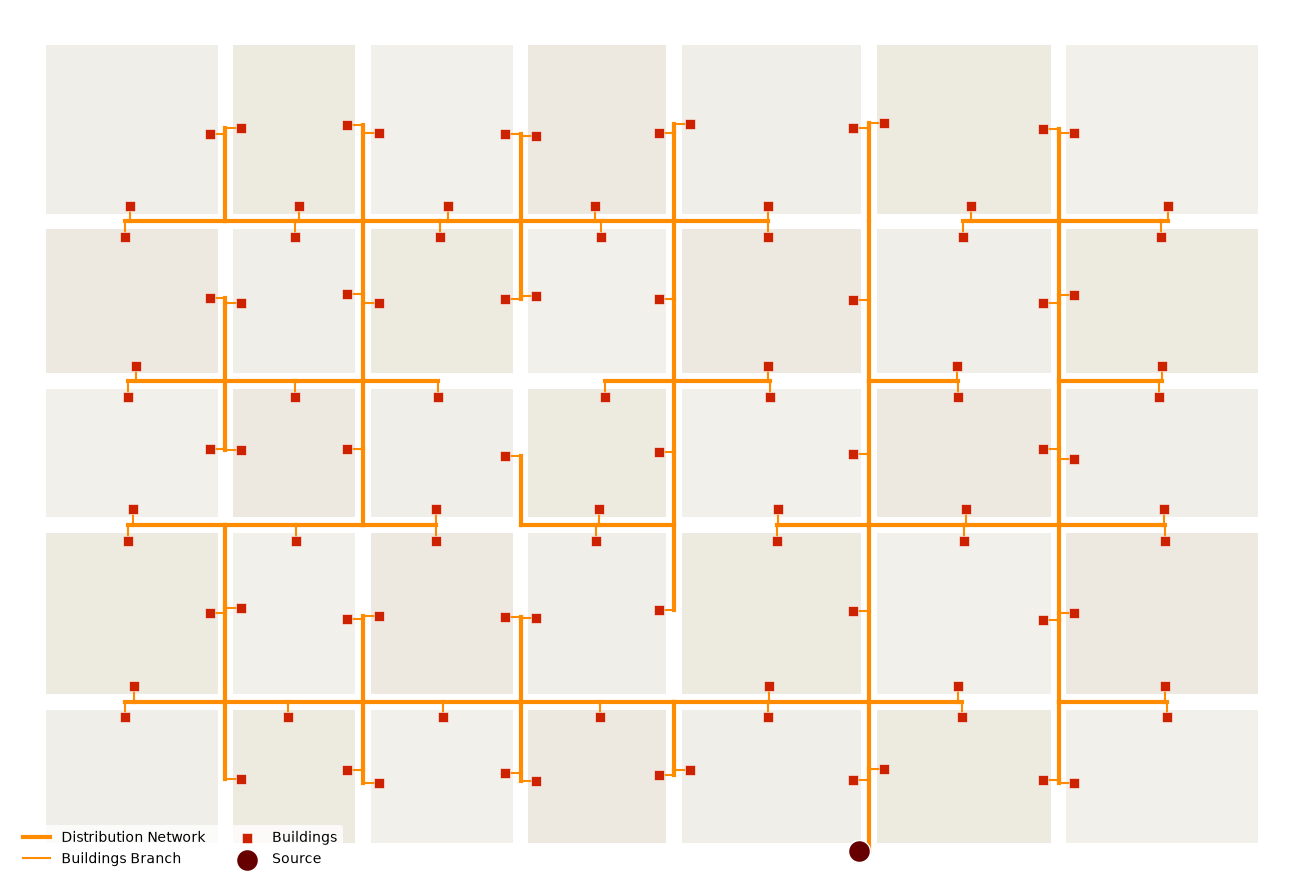

<Axes: >

In [96]:
single_source = [(district.width*2/3, 0)]

builder_a = ThermalNetworkBuilder(district, street_graph, single_source)
builder_a.build_radial_network()
builder_a.stats()
builder_a.plot()